# Attention Residuals: a three-way comparison

This notebook compares three residual mechanisms on small decoder-only, byte-level language models:

| Variant | Residual mechanism | Code |
|---|---|---|
| **Baseline** | standard PreNorm residuals (fixed unit weights) | `GPT`, defined below |
| **DCA** | DeepCrossAttention: GRN-gated access to past layer outputs (Heddes et al., ICML 2025) | `DCAGPT`, defined below |
| **AttnRes** | Full Attention Residuals: softmax attention over all past layer outputs (Kimi Team 2026) | `KARGPT`, implemented from scratch below |

The Kimi Team's core claim is that PreNorm residuals accumulate every layer's output with fixed weight 1, so hidden-state magnitudes grow with depth and deeper layers must produce ever-larger outputs to stay influential ("PreNorm dilution"). AttnRes replaces the fixed sum with learned, input-dependent softmax attention over depth. We check four of the paper's claims at toy scale:

1. **Loss**: comparable or better validation loss (§5.1 of the paper; expected to be noisy at this scale).
2. **Output magnitudes across depth**: the baseline's sublayer output magnitudes should grow with depth, AttnRes should stay bounded (Fig. 5b).
3. **Gradient magnitudes across depth**: the baseline should concentrate large gradients in early layers, AttnRes should be more uniform (Fig. 5c).
4. **Learned depth-attention patterns**: which earlier outputs each layer attends to (Fig. 8).

All three models share the same backbone (PreNorm attention + feed-forward blocks, RoPE, RMSNorm), hyperparameters, seed, and batch order, so differences are attributable to the residual mechanism. The training loop is identical across the three.

## Architecture

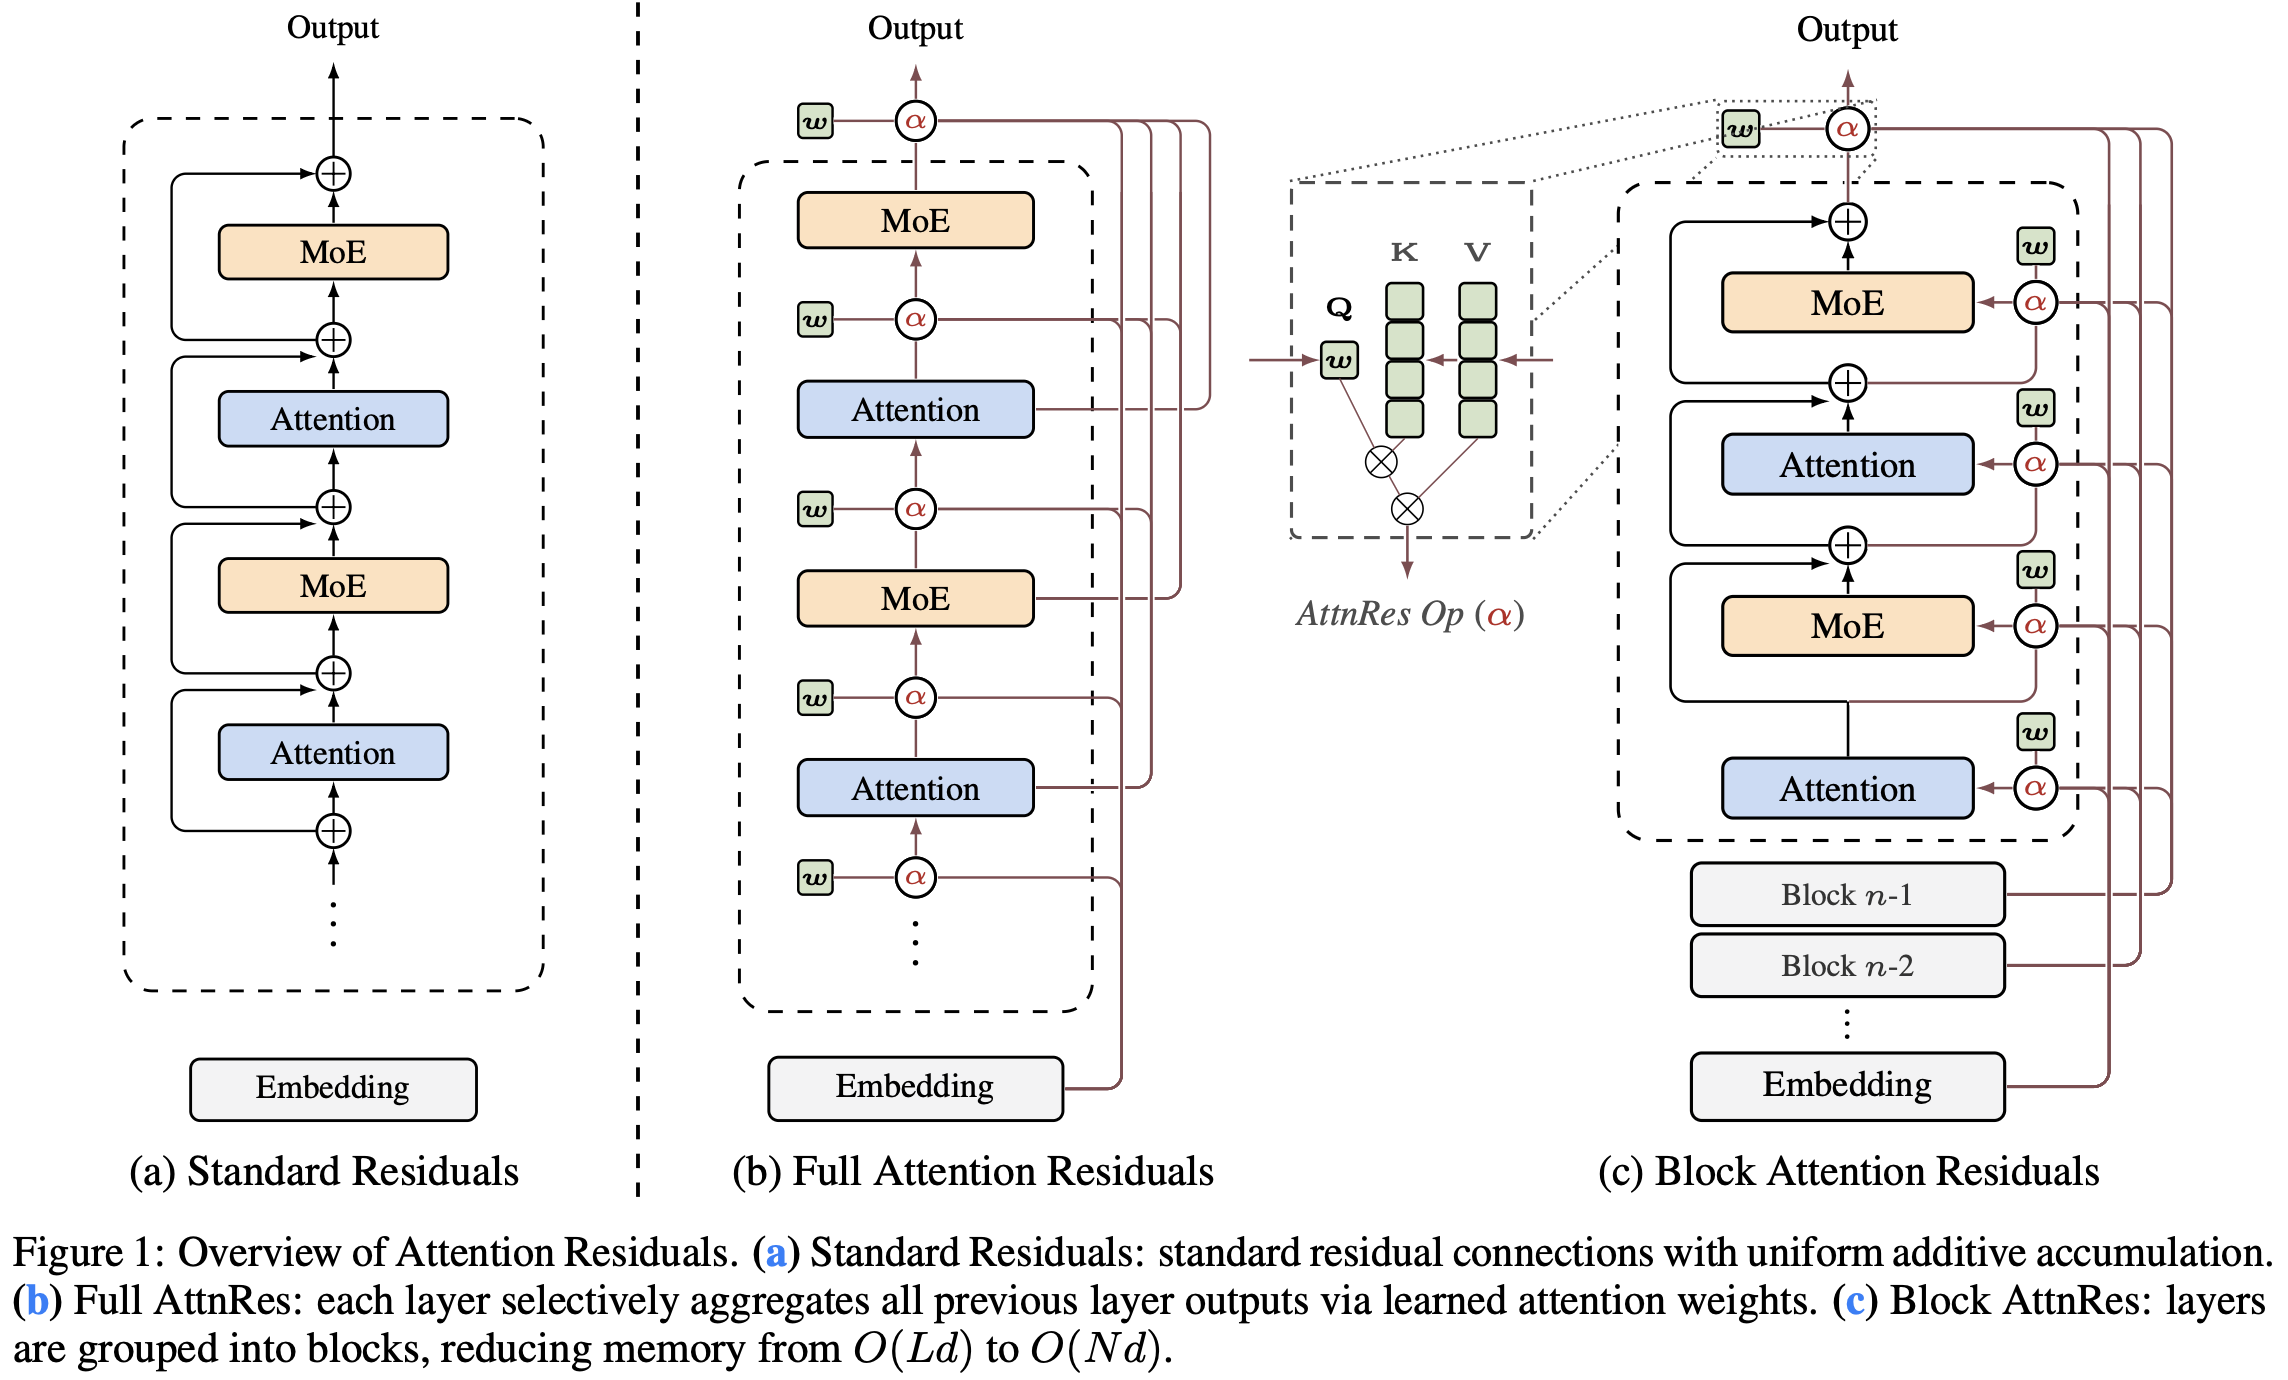

*Figure 1 of Kimi Team 2026.* **(a)** Standard residuals accumulate every layer output additively with fixed unit weight. **(b) Full AttnRes** replaces that fixed sum: each layer attends over *all* preceding layer outputs plus the token embedding, with weights `α` produced by a learned pseudo-query `w` (the *AttnRes Op*, inset). **(c) Block AttnRes** groups the layers into `N` blocks: standard residuals *within* a block, attention only over the `N` block-level summaries.

### Why this notebook implements Full AttnRes, not Block AttnRes

The two are not competing ideas: Block AttnRes is a **scalability variant of the same mechanism**, and the cost it exists to solve is one we do not have.

Attending over all past layer outputs means keeping them around. In ordinary training that is free: the paper notes that "Full AttnRes adds negligible overhead, since the layer outputs it requires are already retained for backpropagation" (§3.1), which is exactly our regime. The problem appears only at large scale, where activation recomputation and pipeline parallelism mean those outputs must be *explicitly* preserved and shipped across pipeline stages, making memory and communication grow as `O(Ld)`. Block AttnRes cuts that to `O(Nd)` by summarizing each block first. (Its inference cost is likewise small, under 2% added latency, but that is a reported consequence, not the motivation.)

The trade is fidelity: Block AttnRes reinstates standard additive residuals *inside* each block and preserves only "most of the gains of full AttnRes." Since we are here to **reproduce the effects** rather than to train a production model, we implement Full AttnRes, where the mechanism is undiluted. At depth 6 on a toy corpus, Block AttnRes would buy us nothing and cost us the very signal we are trying to measure.

This has one consequence worth carrying into Eval 3: the paper's own depth-wise gradient analysis (Fig. 5c) is run on *Block* AttnRes at a much greater depth, so it is not a like-for-like comparison with what we measure here. We return to this where it bites.

## Setup

In [1]:
try:
    import torch, numpy, matplotlib, tqdm, einops, einx, rotary_embedding_torch
    print('dependencies already satisfied')
except ImportError as e:
    print(f'{e.name} missing -- installing dependencies')
    %pip install --quiet torch numpy matplotlib tqdm einops einx rotary-embedding-torch

dependencies already satisfied


In [ ]:
import gzip, math, time, urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch import nn, cat, stack
from torch.nn import Module, ModuleList, Linear, RMSNorm
from torch.optim import Adam
from torch.utils.data import DataLoader, Dataset

from tqdm import tqdm  # plain (not tqdm.auto): the widget bar needs ipywidgets, which
                       # embeds widget state in the .ipynb and fails to render on GitHub

import einx
from einops import rearrange, reduce, einsum
from einops.layers.torch import Rearrange
from rotary_embedding_torch import RotaryEmbedding

DEVICE = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
print(f"torch {torch.__version__} | device: {DEVICE}")

torch 2.13.0+cu130 | device: cuda


### Configuration

Setting `QUICK = True` below switches to a tiny smoke-test configuration (small model, 30 steps) that exercises every cell in a couple of minutes, which is useful to verify the notebook runs end-to-end before committing to the full training run. The full configuration (`QUICK = False`, the default) is a standard small-GPT setup (dim 512, depth 6, seq len 512), with the batch count kept low enough to make the three-model run tractable.

In [ ]:
QUICK = False   # set True for the tiny smoke-test configuration

SEED = 42

# model
NUM_TOKENS = 256          # byte-level vocab
DIM        = 64  if QUICK else 512
DEPTH      = 3   if QUICK else 6
DIM_HEAD   = 16  if QUICK else 64
HEADS      = 4   if QUICK else 8

# training
SEQ_LEN            = 128 if QUICK else 512
BATCH_SIZE         = 4   if QUICK else 8
NUM_BATCHES        = 30  if QUICK else 2000
LR                 = 1e-4
GRAD_CLIP          = 0.5
VALIDATE_EVERY     = 10  if QUICK else 100
RECORD_GRADS_EVERY = 5   if QUICK else 20

# evaluation
NUM_VAL_BATCHES = 2 if QUICK else 8    # fixed set used during training
FINAL_EVAL_N    = 4 if QUICK else 64   # fixed set used for the final loss table

print('quick smoke-test mode' if QUICK else 'full configuration')

full configuration


## Data: enwik8

We use enwik8 (the first 100M bytes of a 2006 English Wikipedia XML dump), a standard byte-level language-modeling benchmark. Tokens are raw bytes, so the vocabulary is 256 and no tokenizer is needed. We take the first 95M bytes and split them 90M train / 5M validation.

The cell below downloads the ~35 MB archive on first run and caches it in `data/`, so re-runs are offline.

In [4]:
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok = True)
ENWIK8_GZ = DATA_DIR / 'enwik8.gz'
ENWIK8_URL = 'https://github.com/lucidrains/deep-cross-attention/raw/main/data/enwik8.gz'

if not ENWIK8_GZ.exists():
    print(f'downloading {ENWIK8_URL} ...')
    urllib.request.urlretrieve(ENWIK8_URL, ENWIK8_GZ)
    print(f'saved to {ENWIK8_GZ} ({ENWIK8_GZ.stat().st_size / 1e6:.1f} MB)')

with gzip.open(ENWIK8_GZ) as f:
    data = np.frombuffer(f.read(int(95e6)), dtype = np.uint8).copy()

np_train, np_valid = np.split(data, [int(90e6)])
data_train, data_val = torch.from_numpy(np_train), torch.from_numpy(np_valid)
print(f'train: {data_train.size(0):,} bytes | val: {data_val.size(0):,} bytes')

train: 90,000,000 bytes | val: 5,000,000 bytes


In [5]:
class TextSamplerDataset(Dataset):
    # every __getitem__ draws a random window of SEQ_LEN + 1 bytes
    # (inputs plus one shifted target)

    def __init__(self, data, seq_len):
        super().__init__()
        self.data = data
        self.seq_len = seq_len

    def __len__(self):
        return self.data.size(0) // self.seq_len

    def __getitem__(self, index):
        rand_start = torch.randint(0, self.data.size(0) - self.seq_len, (1,))
        full_seq = self.data[rand_start : rand_start + self.seq_len + 1].long()
        return full_seq

def sample_val_batches(n, generator):
    # a fixed, pre-sampled validation set so every model is scored on identical data
    batches = []
    for _ in range(n):
        starts = torch.randint(0, data_val.size(0) - SEQ_LEN - 1, (BATCH_SIZE,), generator = generator)
        batches.append(torch.stack([data_val[s : s + SEQ_LEN + 1] for s in starts]).long())
    return batches

g = torch.Generator().manual_seed(SEED)
VAL_BATCHES = sample_val_batches(NUM_VAL_BATCHES, g)
FINAL_EVAL_SET = sample_val_batches(FINAL_EVAL_N, g)
print(f'{NUM_VAL_BATCHES} tracking batches + {FINAL_EVAL_N} final-eval batches, batch size {BATCH_SIZE}, seq len {SEQ_LEN}')

8 tracking batches + 64 final-eval batches, batch size 8, seq len 512


## Model code

The three models are defined inline below, in the order the argument needs them: the shared backbone first, then the standard-residual baseline, then the two learned-residual variants.

- The **backbone** (attention + feed-forward) is shared verbatim by the Baseline and AttnRes, so the only thing that differs between them is the residual rule.
- **`DCAGPT`** needs its own attention and feed-forward: it feeds Q/K/V from *separate* GRN-mixed inputs, so its norms sit inside the projections. Those are prefixed `DCA…` to keep them distinct from the shared ones.
- **`KARGPT`** is the from-scratch Attention Residuals implementation, following the paper's equations.

All three keep to the same structural conventions, so the comparison stays fair.

### Shared backbone: attention and feed-forward

Standard PreNorm sublayers: RMSNorm on the input, causal self-attention with rotary position embeddings via `F.scaled_dot_product_attention`, and a GELU MLP with a 4× expansion. Used unchanged by both the Baseline and AttnRes. Note that neither module adds a residual itself: both simply return their own output `f(x)`, which is what lets the two models differ purely in how those outputs are recombined.

In [6]:
class Attention(Module):
    def __init__(
        self,
        dim,
        dim_head = 64,
        heads = 8
    ):
        super().__init__()
        self.norm = RMSNorm(dim)

        self.heads = heads
        dim_inner = heads * dim_head

        self.rotary_embed = RotaryEmbedding(dim_head)

        self.to_q = nn.Linear(dim, dim_inner, bias = False)
        self.to_k = nn.Linear(dim, dim_inner, bias = False)
        self.to_v = nn.Linear(dim, dim_inner, bias = False)

        self.split_heads = Rearrange('b n (h d) -> b h n d', h = heads)
        self.merge_heads = Rearrange('b h n d -> b n (h d)')

        self.to_out = nn.Linear(dim_inner, dim, bias = False)

    def forward(
        self,
        x
    ):

        x = self.norm(x)

        q = self.to_q(x)
        k = self.to_k(x)
        v = self.to_v(x)

        q, k, v = map(self.split_heads, (q, k, v))

        # relative positions

        q, k = self.rotary_embed.rotate_queries_with_cached_keys(q, k)

        # attention branch

        out = F.scaled_dot_product_attention(
            q, k, v,
            is_causal = True
        )

        out = self.merge_heads(out)

        return self.to_out(out)

def FeedForward(dim, expansion_factor = 4.):
    dim_hidden = int(dim * expansion_factor)

    return nn.Sequential(
        RMSNorm(dim),
        Linear(dim, dim_hidden),
        nn.GELU(),
        Linear(dim_hidden, dim)
    )

### Baseline: standard PreNorm residuals

The reference point. Every sublayer output is added onto one running stream with fixed weight 1:

$$h \leftarrow h + f(h)$$

This is the update rule the Attention Residuals paper argues against: because the weights are fixed at 1 and the stream is never rescaled, its magnitude grows with depth, and a layer that wants to remain influential must emit an ever-larger output to compete with everything already accumulated. Evals 2 and 3 below are direct measurements of that.

In [7]:
class GPT(Module):
    def __init__(
        self,
        num_tokens,
        dim,
        depth,
        dim_head = 64,
        heads = 8,
        ff_expansion_factor = 4.
    ):
        super().__init__()
        self.token_emb = nn.Embedding(num_tokens, dim)

        layers = []
        for _ in range(depth):
            attn = Attention(dim = dim, dim_head = dim_head, heads = heads)
            ff = FeedForward(dim = dim, expansion_factor = ff_expansion_factor)

            layers.append(ModuleList([attn, ff]))

        self.layers = ModuleList(layers)

        self.norm = RMSNorm(dim)
        self.to_logits = Linear(dim, num_tokens, bias = False)

    def forward(
        self,
        ids,
        return_loss = False
    ):
        if return_loss:
            ids, labels = ids[:, :-1], ids[:, 1:]

        tokens = self.token_emb(ids)

        for attn, ff in self.layers:
            tokens = attn(tokens) + tokens
            tokens = ff(tokens) + tokens

        embed = self.norm(tokens)

        logits = self.to_logits(embed)

        if not return_loss:
            return logits

        return F.cross_entropy(rearrange(logits, 'b n l -> b l n'), labels)

### Baseline 2: DeepCrossAttention (Heddes et al., ICML 2025)

DCA is the paper's closest neighbour and our second baseline: instead of one summed stream, each block *re-mixes* the past layer outputs, and (the distinctive part) mixes them **three separate times**, once each for the attention query, key and value. The mixing weights come from a Gated Residual Network (`GRN`): input-dependent, ReLU-gated, initialized near a plain sum (`bias` starts at ones, the projection at std 1e-2), so training begins close to a standard residual and learns to deviate.

For efficiency DCA does not look at *every* past layer, only the first `k` and the last `k` (`select_layers`, here `k = 2`). That bounded window is the main structural difference from AttnRes, which attends over the full depth.

DCA's attention takes three *different* inputs, so unlike the shared backbone above it normalizes inside each of the Q/K/V projections rather than once on a single input; its feed-forward likewise takes its norm from the block (`pre_ff_norm`). Hence the `DCA`-prefixed variants.

In [8]:
class DCAAttention(Module):
    def __init__(
        self,
        dim,
        dim_head = 64,
        heads = 8
    ):
        super().__init__()
        self.norm = RMSNorm(dim)

        self.heads = heads
        dim_inner = heads * dim_head

        self.rotary_embed = RotaryEmbedding(dim_head)

        # q, k and v each arrive as their own GRN mix of the past layers,
        # so each projection carries its own norm

        self.to_q = nn.Sequential(RMSNorm(dim), nn.Linear(dim, dim_inner, bias = False))
        self.to_k = nn.Sequential(RMSNorm(dim), nn.Linear(dim, dim_inner, bias = False))
        self.to_v = nn.Sequential(RMSNorm(dim), nn.Linear(dim, dim_inner, bias = False))

        self.split_heads = Rearrange('b n (h d) -> b h n d', h = heads)
        self.merge_heads = Rearrange('b h n d -> b n (h d)')

        self.to_out = nn.Linear(dim_inner, dim, bias = False)

    def forward(
        self,
        q_input,
        k_input,
        v_input
    ):

        q = self.to_q(q_input)
        k = self.to_k(k_input)
        v = self.to_v(v_input)

        q, k, v = map(self.split_heads, (q, k, v))

        q, k = self.rotary_embed.rotate_queries_with_cached_keys(q, k)

        out = F.scaled_dot_product_attention(
            q, k, v,
            is_causal = True
        )

        out = self.merge_heads(out)

        return self.to_out(out)

def DCAFeedForward(dim, expansion_factor = 4.):
    # no leading norm: the DCA block applies `pre_ff_norm` to the input itself

    dim_hidden = int(dim * expansion_factor)

    return nn.Sequential(
        Linear(dim, dim_hidden),
        nn.GELU(),
        Linear(dim_hidden, dim)
    )

In [9]:
class GRN(Module):
    """Gated Residual Network: input-dependent weights over the past layer outputs.

    Produces `num_outputs` separate mixes (3 for the q/k/v of one DCA block, 1 for the
    final pooling). The `bias` parameter starts at ones and the projection at std 1e-2,
    so at init the mix is close to a plain sum of the past layers.
    """

    def __init__(
        self,
        dim,
        num_layers,
        num_outputs = 1,
        activation = nn.ReLU(),
    ):
        super().__init__()

        self.num_outputs = num_outputs
        self.num_layers = num_layers

        linear = Linear(dim, num_outputs, bias = False)

        nn.init.normal_(linear.weight, std = 1e-2)

        self.to_aggregate = nn.Sequential(
            RMSNorm(dim),
            linear,
            activation,
            Rearrange('... outputs -> outputs ...')
        )

        self.bias = nn.Parameter(torch.ones(num_outputs, num_layers, dim))

    def forward(
        self,
        tokens_across_depth # Float['y b n d']
    ):
        assert self.num_layers == tokens_across_depth.shape[0]

        aggregate = self.to_aggregate(tokens_across_depth)

        aggregate = einx.add('o y b n, o y d -> o y b n d', aggregate, self.bias)

        output = einsum(tokens_across_depth, aggregate, 'y b n d, o y b n d -> o b n d')

        if self.num_outputs == 1:
            output = rearrange(output, '1 ... -> ...')

        return output

class DCABlock(Module):
    def __init__(
        self,
        dim,
        *,
        grn_num_layers,
        dim_head = 64,
        heads = 8,
        ff_expansion_factor = 4.,
        grn_activation = nn.ReLU()
    ):
        super().__init__()

        self.qkv_grn = GRN(dim, num_layers = grn_num_layers, num_outputs = 3, activation = grn_activation)

        self.attn = DCAAttention(dim = dim, dim_head = dim_head, heads = heads)

        self.pre_ff_norm = RMSNorm(dim)

        self.ff = DCAFeedForward(dim = dim, expansion_factor = ff_expansion_factor)

    def forward(
        self,
        tokens_across_depth # Float['depth b n d']
    ):
        q_input, k_input, v_input = self.qkv_grn(tokens_across_depth)

        residual = q_input

        attn_out = self.attn(q_input, k_input, v_input)

        ff_input = self.pre_ff_norm(attn_out + residual)

        ff_out = self.ff(ff_input)

        return ff_out + attn_out

In [10]:
class DCAGPT(Module):
    def __init__(
        self,
        num_tokens,
        dim,
        depth,
        past_layers_k = 2,
        dim_head = 64,
        heads = 8,
        ff_expansion_factor = 4.,
        grn_activation = nn.ReLU()
    ):
        super().__init__()
        self.token_emb = nn.Embedding(num_tokens, dim)

        # `k`: how many past layers a block may look at - the first k and the last k

        self.past_layers_k = past_layers_k

        dca_blocks = []
        for i in range(depth):

            dca = DCABlock(
                dim = dim,
                dim_head = dim_head,
                heads = heads,
                ff_expansion_factor = ff_expansion_factor,
                grn_num_layers = min(past_layers_k * 2, i + 1),
                grn_activation = grn_activation
            )

            dca_blocks.append(dca)

        self.dca_blocks = ModuleList(dca_blocks)

        self.final_grn = GRN(dim, num_layers = min(past_layers_k * 2, depth + 1))

        self.norm = RMSNorm(dim)
        self.to_logits = Linear(dim, num_tokens, bias = False)

    def select_layers(
        self,
        all_tokens_stacked
    ):
        k = self.past_layers_k

        num_layers = all_tokens_stacked.shape[0]

        if num_layers < (k * 2):
            return all_tokens_stacked

        output = cat((
            all_tokens_stacked[:k], # first k layers
            all_tokens_stacked[-k:] # last k layers
        ))

        return output

    def forward(
        self,
        ids,
        return_loss = False
    ):

        if return_loss:
            ids, labels = ids[:, :-1], ids[:, 1:]

        tokens = self.token_emb(ids)

        all_tokens = [tokens]

        for dca_block in self.dca_blocks:

            all_tokens_stacked = stack(all_tokens)

            dca_block_input = self.select_layers(all_tokens_stacked)

            dca_out = dca_block(dca_block_input)

            all_tokens.append(dca_out)

        final_grn_input = self.select_layers(stack(all_tokens))

        pooled_tokens = self.final_grn(final_grn_input)

        embed = self.norm(pooled_tokens)

        logits = self.to_logits(embed)

        if not return_loss:
            return logits

        return F.cross_entropy(rearrange(logits, 'b n l -> b l n'), labels)

### AttnRes: Full Attention Residuals (Kimi Team 2026)

The subject of the notebook, implemented from scratch. The idea is to stop *summing* past layer outputs and start *attending* over them.

Write $v_0$ for the token embedding and $v_i$ for the output of sublayer $i$. Where the baseline forms a layer's input by accumulation ($h_l = \sum_{i<l} v_i$, all weights fixed at 1), AttnRes forms it by softmax attention along the depth axis:

$$k_i = \mathrm{RMSNorm}(v_i) \qquad \alpha_{i \to l} = \underset{i < l}{\mathrm{softmax}}\;(w_l^\top k_i) \qquad h_l = \sum_{i<l} \alpha_{i \to l}\, v_i$$

Three details carry the mechanism, and each is a line in `AttentionResidual` below:

- **the pseudo-query $w_l$**: a plain learned vector per sublayer, *not* a projection of anything the layer computes. That is what makes this cheap: one vector of size `dim` per sublayer, ~0.5% of parameters here.
- **zero initialization of $w_l$**: every logit starts at 0, so the softmax starts *uniform* and training begins from an equal-weight average of the past outputs. The paper (§5) reports this matters for early-training stability.
- **RMSNorm on the keys, not the values**: a layer with a large-magnitude output cannot buy attention mass with that magnitude alone, but the value that gets mixed in is still the un-normalized $v_i$.

Because the weights are a softmax they sum to 1, so a layer's input is a *convex combination* of everything before it: the unbounded accumulation is gone, and with it (per the paper) the growth in hidden-state magnitude with depth. Note the flip side, which becomes the story of Eval 3: there is no identity path anymore either.

`store_attn` is an analysis hook, not part of the method: it records the $\alpha$ weights so Eval 4 can plot them.

In [11]:
# ein notation
# b - batch | n - sequence | d - feature dimension
# y - laYer outputs attended over (the depth axis)

class AttentionResidual(Module):
    """Softmax attention over the embedding + all preceding layer outputs (eq. 1-4)."""

    def __init__(
        self,
        dim
    ):
        super().__init__()

        # the learned pseudo-query w_l - a plain vector, decoupled from the layer's forward computation
        # must be zero-initialized: attention starts uniform, so training begins from an
        # equal-weight average of past outputs (§5, prevents early training volatility)

        self.pseudo_query = nn.Parameter(torch.zeros(dim))

        # keys are RMSNorm'ed so layers with large-magnitude outputs
        # cannot dominate the attention weights (eq. 2)

        self.norm = RMSNorm(dim)

        # analysis hook: when store_attn is set, forward keeps the depth-attention
        # weights α_{i→l} averaged over batch and sequence (fig. 8 style plots)

        self.store_attn = False
        self.stored_attn = None

    def forward(
        self,
        values # Float['y b n d'] - token embedding v_0 + all preceding layer outputs v_i
    ):
        keys = self.norm(values)

        sim = einsum(self.pseudo_query, keys, 'd, y b n d -> y b n')

        attn = sim.softmax(dim = 0)

        if self.store_attn:
            self.stored_attn = reduce(attn.detach(), 'y b n -> y', 'mean')

        return einsum(attn, values, 'y b n, y b n d -> b n d')

The model itself then has no residual stream at all, just a growing list of layer outputs, with an `AttentionResidual` in front of every consumer of them.

Two consequences of the paper's notation are worth pointing out in the code. First, each self-attention and each MLP counts as its **own layer** (§2), so every sublayer gets its own pseudo-query, and the depth axis of the attention has `2 × depth + 1` entries, not `depth + 1`. Second, the **output head aggregates too** (Fig. 1b): the final hidden state is itself an attention over all layer outputs, not just the last one.

In [12]:
class KARGPT(Module):
    """KAR = Kimi Attention Residuals. Full AttnRes: the fixed residual accumulation
    h_l = Σ v_i is replaced by softmax attention over the embedding + all preceding outputs."""

    def __init__(
        self,
        num_tokens,
        dim,
        depth,
        dim_head = 64,
        heads = 8,
        ff_expansion_factor = 4.
    ):
        super().__init__()
        self.token_emb = nn.Embedding(num_tokens, dim)

        # each self-attention and each MLP counts as its own layer (§2 notation),
        # so every sublayer gets its own pseudo-query / AttnRes op
        # (the very first op sees only v_0, where softmax over one element is 1 -
        # an identity with an untrained pseudo-query, kept for uniformity)

        layers = []
        for _ in range(depth):
            attn_res = AttentionResidual(dim)
            attn = Attention(dim = dim, dim_head = dim_head, heads = heads)

            ff_res = AttentionResidual(dim)
            ff = FeedForward(dim = dim, expansion_factor = ff_expansion_factor)

            layers.append(ModuleList([attn_res, attn, ff_res, ff]))

        self.layers = ModuleList(layers)

        # the output head aggregates over all layer outputs as well (fig. 1b)

        self.final_attn_res = AttentionResidual(dim)

        self.norm = RMSNorm(dim)
        self.to_logits = Linear(dim, num_tokens, bias = False)

    def forward(
        self,
        ids,
        return_loss = False
    ):
        if return_loss:
            ids, labels = ids[:, :-1], ids[:, 1:]

        tokens = self.token_emb(ids)

        # v_0 is the token embedding (eq. 3)

        values = [tokens]

        for attn_res, attn, ff_res, ff in self.layers:

            # h_l = Σ α_{i→l} · v_i (eq. 4), then v_l = f_l(h_l) - the layer output
            # alone is stored, there is no additive residual anymore

            h = attn_res(stack(values))
            values.append(attn(h))

            h = ff_res(stack(values))
            values.append(ff(h))

        pooled = self.final_attn_res(stack(values))

        embed = self.norm(pooled)

        logits = self.to_logits(embed)

        if not return_loss:
            return logits

        return F.cross_entropy(rearrange(logits, 'b n l -> b l n'), labels)

### Building the three models

To recap what differs, now that all three are on the table: every model's layer input is some combination of the embedding and the past sublayer outputs, and they disagree only on how the combining weights are chosen:

| | weights over past outputs | who may be looked at | identity path? |
|---|---|---|---|
| **Baseline** | fixed at 1 | the single accumulated stream | yes |
| **DCA** | input-dependent, ReLU-gated (GRN), separately per Q/K/V | first `k` + last `k` layers | near-identity at init |
| **AttnRes** | input-dependent, softmax → sums to 1 | *all* past sublayers + embedding | no |

Same seed, so the init RNG stream is identical across variants. Parameter counts differ slightly (DCA's GRNs, AttnRes' pseudo-queries and key-norms); at this scale AttnRes' overhead is ~0.5% of parameters. Worth remembering that the paper calls it "negligible" at 48B scale, where it genuinely is.

In [13]:
def build_model(name):
    torch.manual_seed(SEED)  # identical init RNG stream per variant
    common = dict(num_tokens = NUM_TOKENS, dim = DIM, depth = DEPTH, dim_head = DIM_HEAD, heads = HEADS)
    if name == 'Baseline':
        return GPT(**common)
    if name == 'DCA':
        return DCAGPT(**common, past_layers_k = 2)
    if name == 'AttnRes':
        return KARGPT(**common)
    raise ValueError(name)

MODEL_NAMES = ['Baseline', 'DCA', 'AttnRes']

for name in MODEL_NAMES:
    n_params = sum(p.numel() for p in build_model(name).parameters())
    print(f'{name:>9}: {n_params:,} params')

 Baseline: 19,158,720 params
      DCA: 19,210,944 params


  AttnRes: 19,172,032 params


## Training

A plain single-device training loop, shared by all three models: Adam at `1e-4`, gradient-norm clipping at `0.5`, and random-window batches.

The one addition is instrumentation. Every `RECORD_GRADS_EVERY` steps we record each transformer block's parameter-gradient norm **before clipping** (the paper's Fig. 5c analog), and every `VALIDATE_EVERY` steps the loss on the fixed validation batches.

`torch.manual_seed(SEED)` is called right before each model's loop, and batch sampling draws from the global RNG (no dropout or other RNG consumers in the forward pass), so **all three models see exactly the same batches in the same order**.

In [14]:
def cycle(loader):
    while True:
        for batch in loader:
            yield batch

def transformer_blocks(model):
    # per-block parameter grouping, in depth order; for KARGPT a block also
    # contains its two AttnRes ops, for DCAGPT its GRNs
    return model.dca_blocks if isinstance(model, DCAGPT) else model.layers

def block_grad_norms(blocks):
    return [
        math.sqrt(sum(p.grad.pow(2).sum().item() for p in blk.parameters() if p.grad is not None))
        for blk in blocks
    ]

@torch.no_grad()
def mean_loss(model, batches):
    model.eval()
    return float(np.mean([model(b.to(DEVICE), return_loss = True).item() for b in batches]))

In [15]:
def train(model, num_batches = NUM_BATCHES):
    model.to(DEVICE)
    opt = Adam(model.parameters(), lr = LR)
    blocks = list(transformer_blocks(model))

    torch.manual_seed(SEED)  # -> identical batch order across models
    loader = cycle(DataLoader(TextSamplerDataset(data_train, SEQ_LEN), batch_size = BATCH_SIZE))

    hist = {'train_loss': [], 'val_step': [], 'val_loss': [], 'grad_step': [], 'grad_norms': []}

    for step in tqdm(range(1, num_batches + 1), desc = type(model).__name__):
        model.train()
        batch = next(loader).to(DEVICE)

        loss = model(batch, return_loss = True)
        opt.zero_grad()
        loss.backward()

        if step % RECORD_GRADS_EVERY == 0:
            hist['grad_step'].append(step)
            hist['grad_norms'].append(block_grad_norms(blocks))

        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        opt.step()

        hist['train_loss'].append(loss.item())
        if step % VALIDATE_EVERY == 0:
            hist['val_step'].append(step)
            hist['val_loss'].append(mean_loss(model, VAL_BATCHES))

    hist['grad_norms'] = np.array(hist['grad_norms'])
    return hist

In [16]:
models, histories = {}, {}

for name in MODEL_NAMES:
    model = build_model(name)
    t0 = time.time()
    histories[name] = train(model)
    models[name] = model
    print(f'{name:>9}: {time.time() - t0:5.0f}s | final tracked val loss {histories[name]["val_loss"][-1]:.4f}')

GPT:   0%|          | 0/2000 [00:00<?, ?it/s]

GPT:   0%|          | 1/2000 [00:00<08:59,  3.70it/s]

GPT:   0%|          | 7/2000 [00:00<01:29, 22.33it/s]

GPT:   1%|          | 13/2000 [00:00<00:59, 33.35it/s]

GPT:   1%|          | 19/2000 [00:00<00:49, 40.26it/s]

...

KARGPT: 100%|█████████▉| 1992/2000 [00:56<00:00, 36.05it/s]

KARGPT: 100%|█████████▉| 1996/2000 [00:56<00:00, 36.08it/s]

KARGPT: 100%|██████████| 2000/2000 [00:56<00:00, 30.82it/s]

KARGPT: 100%|██████████| 2000/2000 [00:56<00:00, 35.12it/s]

  AttnRes:    57s | final tracked val loss 1.4973


## Results

In [17]:
# shared plot style: fixed color per variant,
# recessive grid and axes, direct end-of-line labels next to a legend

COLORS = {'Baseline': '#2a78d6', 'DCA': '#1baf7a', 'AttnRes': '#eda100'}
INK, INK2, MUTED, GRID, AXIS = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'text.color': INK, 'font.size': 11, 'lines.linewidth': 2,
    'legend.frameon': False,
})

def end_labels(ax, items):
    # direct labels at the line ends, nudged apart vertically so converging
    # curves stay readable; items: list of (x, y, name)
    ax.autoscale_view()
    lo, hi = ax.get_ylim()
    gap = 0.06 * (hi - lo)
    prev = None
    for x, y, name in sorted(items, key = lambda t: t[1]):
        y_lbl = y if prev is None else max(y, prev + gap)
        prev = y_lbl
        ax.annotate(name, (x, y_lbl), xytext = (6, 0), textcoords = 'offset points',
                    color = COLORS[name], va = 'center', fontweight = 'bold', fontsize = 10)
    if prev is not None and prev + gap > hi:
        ax.set_ylim(lo, prev + gap)  # keep nudged labels inside the axes

## Eval 1: loss

Left: training loss, lightly drawn raw with a moving average on top. Right: loss on the fixed validation batches.

**Caveat:** at this scale the loss comparison is *noisy*: the paper's gaps are ~0.02 nats for models with hundreds of millions of parameters trained on tens of billions of tokens; our run covers a few million tokens on ~25M-parameter models with a single seed. "Comparable loss, trains stably" is the honest bar here (and the final table below reports the batch-level standard deviation to make the noise visible). The structural claims in Evals 2–4 are where toy scale can genuinely reproduce the paper.

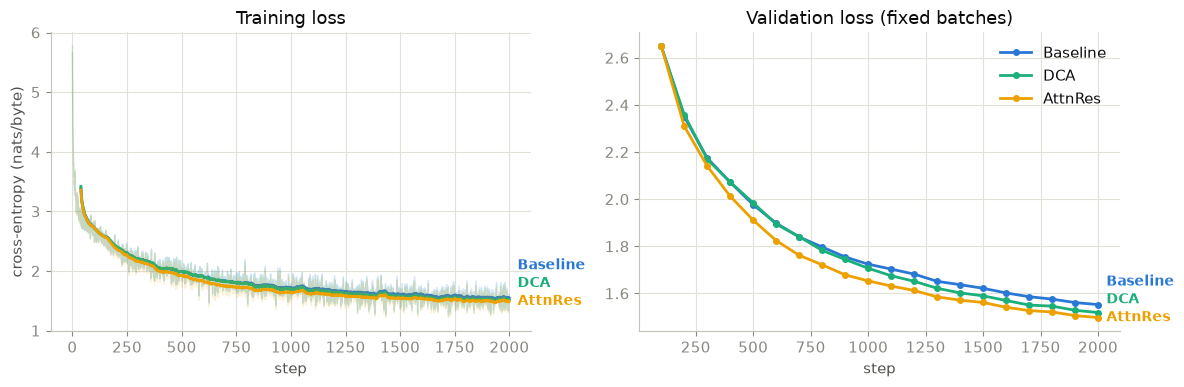

In [18]:
def smooth(x, frac = 0.02):
    w = max(1, int(len(x) * frac))
    return np.convolve(x, np.ones(w) / w, mode = 'valid')

from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(1, 2, figsize = (12, 4))
train_ends, val_ends = [], []

for name in MODEL_NAMES:
    h, c = histories[name], COLORS[name]
    axes[0].plot(h['train_loss'], color = c, alpha = 0.15, linewidth = 1)
    s = smooth(h['train_loss'])
    axes[0].plot(np.arange(len(s)) + (len(h['train_loss']) - len(s)), s, color = c)
    train_ends.append((len(h['train_loss']) - 1, s[-1], name))

    axes[1].plot(h['val_step'], h['val_loss'], color = c, marker = 'o', markersize = 4, label = name)
    val_ends.append((h['val_step'][-1], h['val_loss'][-1], name))

end_labels(axes[0], train_ends)
end_labels(axes[1], val_ends)
axes[0].set(title = 'Training loss', xlabel = 'step', ylabel = 'cross-entropy (nats/byte)')
axes[1].set(title = 'Validation loss (fixed batches)', xlabel = 'step')
axes[1].xaxis.set_major_locator(MaxNLocator(integer = True))
axes[1].legend(loc = 'upper right')
fig.tight_layout()

In [19]:
print(f'final loss over {FINAL_EVAL_N} fixed validation batches (mean ± std across batches):\n')
for name, model in models.items():
    model.eval()
    with torch.no_grad():
        losses = [model(b.to(DEVICE), return_loss = True).item() for b in FINAL_EVAL_SET]
    mean, std = np.mean(losses), np.std(losses)
    print(f'{name:>9}: {mean:.4f} ± {std:.4f} nats/byte  ({mean / math.log(2):.4f} bits/byte)')

final loss over 64 fixed validation batches (mean ± std across batches):



 Baseline: 1.5536 ± 0.0796 nats/byte  (2.2414 bits/byte)


      DCA: 1.5222 ± 0.0767 nats/byte  (2.1961 bits/byte)


  AttnRes: 1.4989 ± 0.0791 nats/byte  (2.1624 bits/byte)


## Eval 2: sublayer output magnitudes across depth

Paper claim (Fig. 5b): with standard residuals, hidden-state magnitude grows with depth, so deeper layers are "compelled to learn increasingly large outputs to remain influential" against their fixed-scale normalized inputs. AttnRes removes the unbounded accumulation, so output magnitudes should stay bounded.

We measure the mean per-token L2 norm of every attention and feed-forward sublayer's output (the layer's *contribution* `f(·)`, not the accumulated stream) on the fixed validation batches, via forward hooks; no model code is touched.

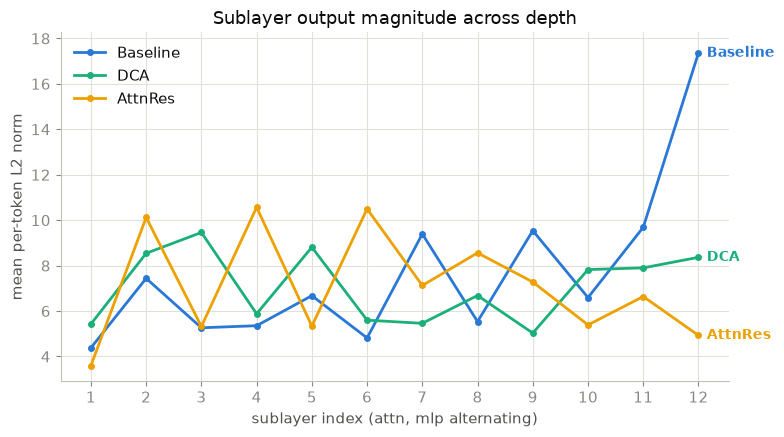

In [20]:
def sublayer_modules(model):
    # each variant's attention + feed-forward modules, in depth order
    mods = []
    if isinstance(model, DCAGPT):
        for blk in model.dca_blocks:
            mods += [blk.attn, blk.ff]
    elif isinstance(model, KARGPT):
        for _attn_res, attn, _ff_res, ff in model.layers:
            mods += [attn, ff]
    else:
        for attn, ff in model.layers:
            mods += [attn, ff]
    return mods

@torch.no_grad()
def output_magnitudes(model):
    mods = sublayer_modules(model)
    sums = np.zeros(len(mods))

    def make_hook(idx):
        def hook(module, args, out):
            sums[idx] += out.detach().float().norm(dim = -1).mean().item()
        return hook

    handles = [m.register_forward_hook(make_hook(i)) for i, m in enumerate(mods)]
    model.eval()
    for b in VAL_BATCHES:
        model(b.to(DEVICE))
    for h in handles:
        h.remove()
    return sums / len(VAL_BATCHES)

fig, ax = plt.subplots(figsize = (8, 4.5))
xs = np.arange(1, 2 * DEPTH + 1)
ends = []
for name, model in models.items():
    mags = output_magnitudes(model)
    ax.plot(xs, mags, color = COLORS[name], marker = 'o', markersize = 4, label = name)
    ends.append((xs[-1], mags[-1], name))

end_labels(ax, ends)
ax.set(title = 'Sublayer output magnitude across depth',
       xlabel = 'sublayer index (attn, mlp alternating)',
       ylabel = 'mean per-token L2 norm')
ax.set_xticks(xs)
ax.legend(loc = 'upper left')
fig.tight_layout()

## Eval 3: gradient magnitudes across depth

Paper claim (Fig. 5c): with all residual weights fixed to 1, the baseline has no way to regulate gradient flow across depth, so the earliest layers receive disproportionately large gradients; AttnRes' learned softmax weights "introduce competition among sources for probability mass," giving a substantially more uniform gradient distribution.

**Two caveats on how far this comparison can carry.** The paper's Fig. 5c plots *Block* AttnRes against the baseline on a model roughly 24 blocks deep; we run *Full* AttnRes at depth 6. Both the variant and the depth differ, and depth is exactly the axis the effect is supposed to grow along; six blocks may simply not give accumulation enough room to dilute.

We recorded each block's parameter-gradient norm (pre-clipping) every `RECORD_GRADS_EVERY` steps during training; the plot averages over the second half of training, once dynamics have settled.

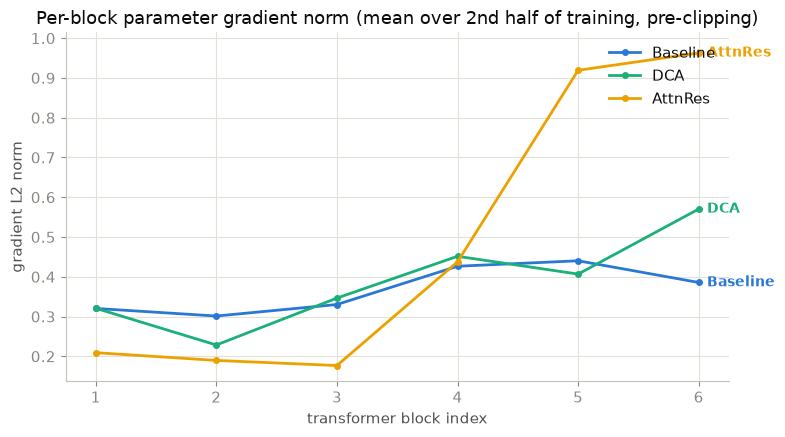

In [21]:
fig, ax = plt.subplots(figsize = (8, 4.5))
xs = np.arange(1, DEPTH + 1)
ends = []
for name in MODEL_NAMES:
    gn = histories[name]['grad_norms']
    settled = gn[len(gn) // 2 :].mean(axis = 0)
    ax.plot(xs, settled, color = COLORS[name], marker = 'o', markersize = 4, label = name)
    ends.append((xs[-1], settled[-1], name))

end_labels(ax, ends)
ax.set(title = 'Per-block parameter gradient norm (mean over 2nd half of training, pre-clipping)',
       xlabel = 'transformer block index', ylabel = 'gradient L2 norm')
ax.set_xticks(xs)
ax.legend(loc = 'upper right')
fig.tight_layout()

### Eval 3b: gradient *flowing through* depth

The plot above measures each block's **parameter**-gradient norm. But the paper's mechanism (§2) is about the gradient that propagates *backward through the residual path*: the identity connection is described as "a direct gradient path from the loss to any layer regardless of depth," which is a statement about `∂L/∂h`, not about parameter gradients. The two need not agree, and below they do not.

So we also measure the backward counterpart of Eval 2: on the same sublayer modules and the same fixed batches, the mean per-token L2 norm of the gradient **arriving at each sublayer's output**, `∂L/∂out`, via backward hooks. Forward magnitude and backward gradient on the same tensor, read off the trained models, with no retraining and no model code touched.

Three things to read off the curve below.

**The baseline does show the paper's shape here, mildly.** `∂L/∂out` is largest at the earliest sublayers and falls steadily with depth (≈2.0×10⁻⁴ → ≈0.7×10⁻⁴, a factor of ~2.9). This is exactly the pile-up the paper diagnoses: the identity path hands the gradient backward essentially unchanged while every sublayer adds its own contribution on the way down, so the bottom of the stack accumulates the most. At depth 6 the effect is present but gentle, nothing like Fig. 5c, whose x-axis runs past block 20.

**AttnRes does not flatten that tilt; it inverts it, and widens the spread.** Its gradient is *smallest* at the early sublayers (≈0.5–1.2×10⁻⁴) and *largest* at the deepest (≈2.6–3.2×10⁻⁴): a ~6.3× spread, the widest of the three, where the claim predicts the narrowest. With no identity path, an early source is reached only through softmax weights that sum to 1 over a growing set of sources, so each hop backward *attenuates* rather than preserves. The "competition among sources for probability mass" is real and visible in the Eval 4 heatmap, but at depth 6 it starves the early layers instead of equalizing them. DCA lands in between (~2.2× spread), non-monotone, with a hump in the middle blocks and no clear tilt with depth.

**AttnRes alone has a pronounced attention/MLP sawtooth within each block.** The baseline's and DCA's two sublayers of a block receive near-identical gradient; AttnRes' differ by ~1.5–1.9× in the lower blocks (attention above MLP), reversing in the top two. Its sublayers are genuinely separate sources competing for mass, not two halves of one accumulating stream.

**Why this is not the same picture as Eval 3.** There the baseline was *flat* across blocks (~0.30–0.44); here it clearly declines with depth. Both are true, and Eval 2 reconciles them: a parameter gradient scales with the forward activation feeding the layer as well as the backward gradient arriving at it, and in the baseline those activations *grow* with depth (~4 → ~17), which roughly cancels the decaying `∂L/∂out`. AttnRes, whose forward magnitudes stay in a bounded band, has no such cancellation, so its rise with depth survives in both plots. The disagreement is a real property of the models, not an artifact of either probe.

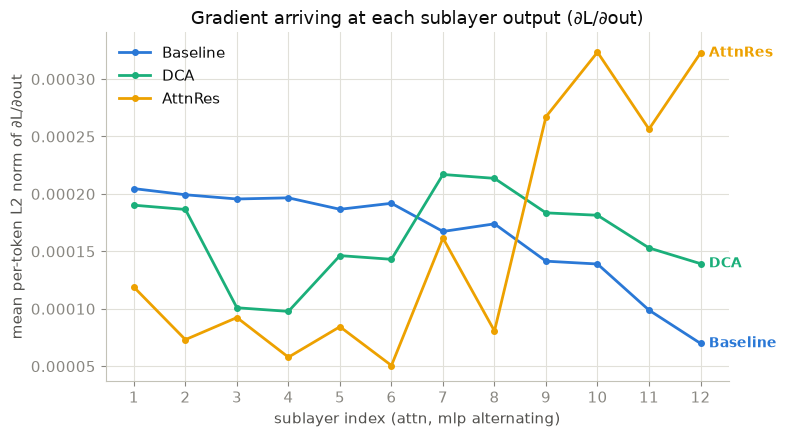

In [22]:
def sublayer_grad_norms(model, batches):
    # backward counterpart of output_magnitudes(): the gradient *arriving at* each
    # sublayer's output, dL/d(out), via backward hooks on the same modules
    mods = sublayer_modules(model)
    sums = np.zeros(len(mods))

    def make_hook(idx):
        def hook(module, grad_input, grad_output):
            g = grad_output[0]
            if g is not None:
                sums[idx] += g.detach().float().norm(dim = -1).mean().item()
        return hook

    handles = [m.register_full_backward_hook(make_hook(i)) for i, m in enumerate(mods)]
    model.eval()
    model.zero_grad(set_to_none = True)
    for b in batches:
        model(b.to(DEVICE), return_loss = True).backward()
    for h in handles:
        h.remove()
    model.zero_grad(set_to_none = True)  # leave no stale grads on the trained models
    return sums / len(batches)

fig, ax = plt.subplots(figsize = (8, 4.5))
xs = np.arange(1, 2 * DEPTH + 1)
ends = []
for name in MODEL_NAMES:
    g = sublayer_grad_norms(models[name], VAL_BATCHES)
    ax.plot(xs, g, color = COLORS[name], marker = 'o', markersize = 4, label = name)
    ends.append((xs[-1], g[-1], name))

end_labels(ax, ends)
ax.set(title = 'Gradient arriving at each sublayer output (∂L/∂out)',
       xlabel = 'sublayer index (attn, mlp alternating)',
       ylabel = 'mean per-token L2 norm of ∂L/∂out')
ax.set_xticks(xs)
ax.legend(loc = 'upper left')
fig.tight_layout()

## Eval 4: learned depth-attention patterns

The paper's Fig. 8 visualizes the learned weights `α_{i→l}`: how each layer distributes its attention over previous sources. Their observations: **locality** (each layer attends most to its immediate predecessor), **embedding persistence** (source 0 keeps non-trivial weight throughout), and occasional learned skip connections.

`AttentionResidual` can record its softmax weights (averaged over batch and sequence positions) during a forward pass. Rows are consuming ops (each block's attn and mlp, plus the final aggregation before the head); columns are sources (the embedding plus every earlier sublayer output); the upper triangle is structurally empty (a layer cannot attend to what hasn't been computed). Note the first row is trivially 1, a softmax over a single source.

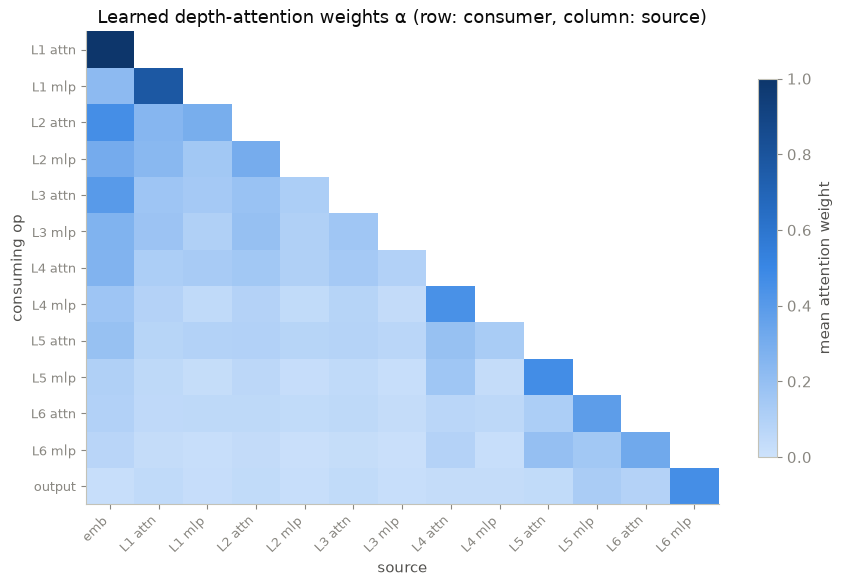

In [23]:
from matplotlib.colors import LinearSegmentedColormap

kar = models['AttnRes']

ops, row_labels = [], []
for i, (attn_res, _attn, ff_res, _ff) in enumerate(kar.layers):
    ops += [attn_res, ff_res]
    row_labels += [f'L{i + 1} attn', f'L{i + 1} mlp']
ops.append(kar.final_attn_res)
row_labels.append('output')

for op in ops:
    op.store_attn = True
with torch.no_grad():
    kar.eval()
    kar(VAL_BATCHES[0].to(DEVICE))
for op in ops:
    op.store_attn = False

n_sources = 2 * DEPTH + 1
weights = np.full((len(ops), n_sources), np.nan)
for r, op in enumerate(ops):
    w = op.stored_attn.float().cpu().numpy()
    weights[r, : len(w)] = w

col_labels = ['emb'] + row_labels[:-1]

BRAND_BLUES = LinearSegmentedColormap.from_list('brand_blues', [
    '#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b'])

fig, ax = plt.subplots(figsize = (9, 6))
im = ax.imshow(weights, cmap = BRAND_BLUES, vmin = 0, aspect = 'auto')
ax.set_xticks(range(n_sources), col_labels, rotation = 45, ha = 'right', fontsize = 9)
ax.set_yticks(range(len(ops)), row_labels, fontsize = 9)
ax.set(title = 'Learned depth-attention weights α (row: consumer, column: source)',
       xlabel = 'source', ylabel = 'consuming op')
ax.grid(False)
fig.colorbar(im, ax = ax, label = 'mean attention weight', shrink = 0.8)
fig.tight_layout()

## Discussion

Three of the four claims reproduce at toy scale; one does not.

1. **Loss** ✓: all three variants train stably, and the ordering (AttnRes 1.499 < DCA 1.522 < Baseline 1.554 nats/byte) matches the paper's direction, with the validation curves separating early and never crossing. Given the single seed and the scale, the honest reading is the modest one, "comparable loss, trains stably", rather than a reproduction of the paper's compute-advantage numbers. Note also that AttnRes is *not* free here: 57s vs. the baseline's 38s, so it wins per step, not per second.
2. **Output magnitudes** ✓: the baseline climbs from ~4 to ~17 across depth, with a sharp jump in the final sublayer, while AttnRes stays in a bounded band and ends roughly where it started. This is PreNorm dilution in miniature, and it is the cleanest reproduction in the notebook: it follows from the update rule itself, so it survives the drop in scale.
3. **Gradient magnitudes** ✗: **the AttnRes half does not reproduce.** The claim has two halves (a baseline that concentrates gradient in its earliest layers, and an AttnRes that is more uniform), and the two probes disagree about the first one, so they are worth separating.

   *The baseline.* On **parameter** gradients (Eval 3) it is essentially flat across blocks (~0.30–0.44), with no sign of the early-layer pile-up the paper describes. On the **gradient flowing backward** (Eval 3b) it is not flat at all: `∂L/∂out` is largest at the earliest sublayers and falls steadily with depth (≈2.0×10⁻⁴ down to ≈0.7×10⁻⁴, a factor of ~2.9), which *is* the paper's diagnosis, just mild at depth 6. Eval 2 reconciles the two readings: a parameter gradient scales with the forward activation feeding a layer as well as with the gradient arriving at it, and the baseline's activations *grow* with depth (~4 to ~17), roughly cancelling the decaying `∂L/∂out`. The flat curve in Eval 3 is therefore the product of two opposing depth trends, not evidence that gradient flow is uniform.

   *AttnRes.* Here the claim fails on both probes, and in the same direction. Parameter gradients rise about 5× with depth (~0.18 to ~0.95), and `∂L/∂out` runs from ≈0.5–1.2×10⁻⁴ at the early sublayers up to ≈2.6–3.2×10⁻⁴ at the deepest: a ~6.3× spread. AttnRes does not flatten the baseline's tilt, it inverts it and widens it, ending up the *least* uniform of the three where the paper predicts the most (DCA lands in between, at ~2.2×).

   We attribute this to **scale**, and specifically to depth. AttnRes has no identity path at all, so it reaches an early source only through softmax weights that sum to 1 over a growing set of sources, and each hop backward attenuates rather than preserves; the very "competition among sources for probability mass" that the paper credits for uniformity at depth instead starves the early layers at depth 6. Our Eval 4 heatmap shows the weights that do it (late consumers give early sources ~0.05–0.1 mass). The baseline's identity path, by contrast, hands `∂L/∂h` backward essentially unchanged, and six blocks give that accumulation too little room to build the pile-up the paper reports at ~24 (see Fig. 5c of Kimi Team 2026, whose x-axis runs past block 20).

   Two confounds compound the depth gap and are worth stating plainly: the paper's Fig. 5c compares **Block** AttnRes, whereas we implement **Full** AttnRes, and Block AttnRes explicitly *resets* accumulation at block boundaries. So we are not measuring the same variant at the same depth, and we should not expect to.

4. **Depth-attention heatmap** ✓: both signatures the paper describes are present: locality (every consumer attends most to its immediate predecessor) and embedding persistence (the `emb` column retains real weight several layers in). A pleasing extra: the `attn` rows lean on the embedding while the `mlp` rows lean on their immediate predecessor.

**Limitations worth stating plainly:** single seed; ~19M-parameter models for 2,000 steps vs. the paper's multi-billion-parameter, trillion-token runs; depth 6 vs. ~24, which is precisely the axis claim 3 depends on; the paper's headline model uses *Block* AttnRes (out of scope here; we implement Full AttnRes); and AttnRes' parameter overhead (~0.5% here) is only truly negligible at scale. The structural claims (2 and 4) are the ones toy scale can genuinely test, and those are the ones that hold.

---

## References and credits

**Papers**

- Kimi Team (2026). *Attention Residuals* (Technical Report). The primary paper; `KARGPT` above is a from-scratch implementation of its Full AttnRes.
- Heddes, M., Javanmard, A., Axiotis, K., Fu, G., Bateni, M. H., Mirrokni, V. (2025). *DeepCrossAttention: Supercharging Transformer Residual Connections.* ICML 2025. [arXiv:2502.06785](https://arxiv.org/abs/2502.06785). The DCA baseline.

**Code**

The `GPT` and `DCAGPT` model definitions and the training loop are adapted from Phil Wang's (lucidrains) [`deep-cross-attention`](https://github.com/lucidrains/deep-cross-attention), which is released under the **MIT License** (Copyright © 2025 Phil Wang). The enwik8 archive is downloaded from the same repository. The AttnRes implementation (`AttentionResidual`, `KARGPT`) is our own.